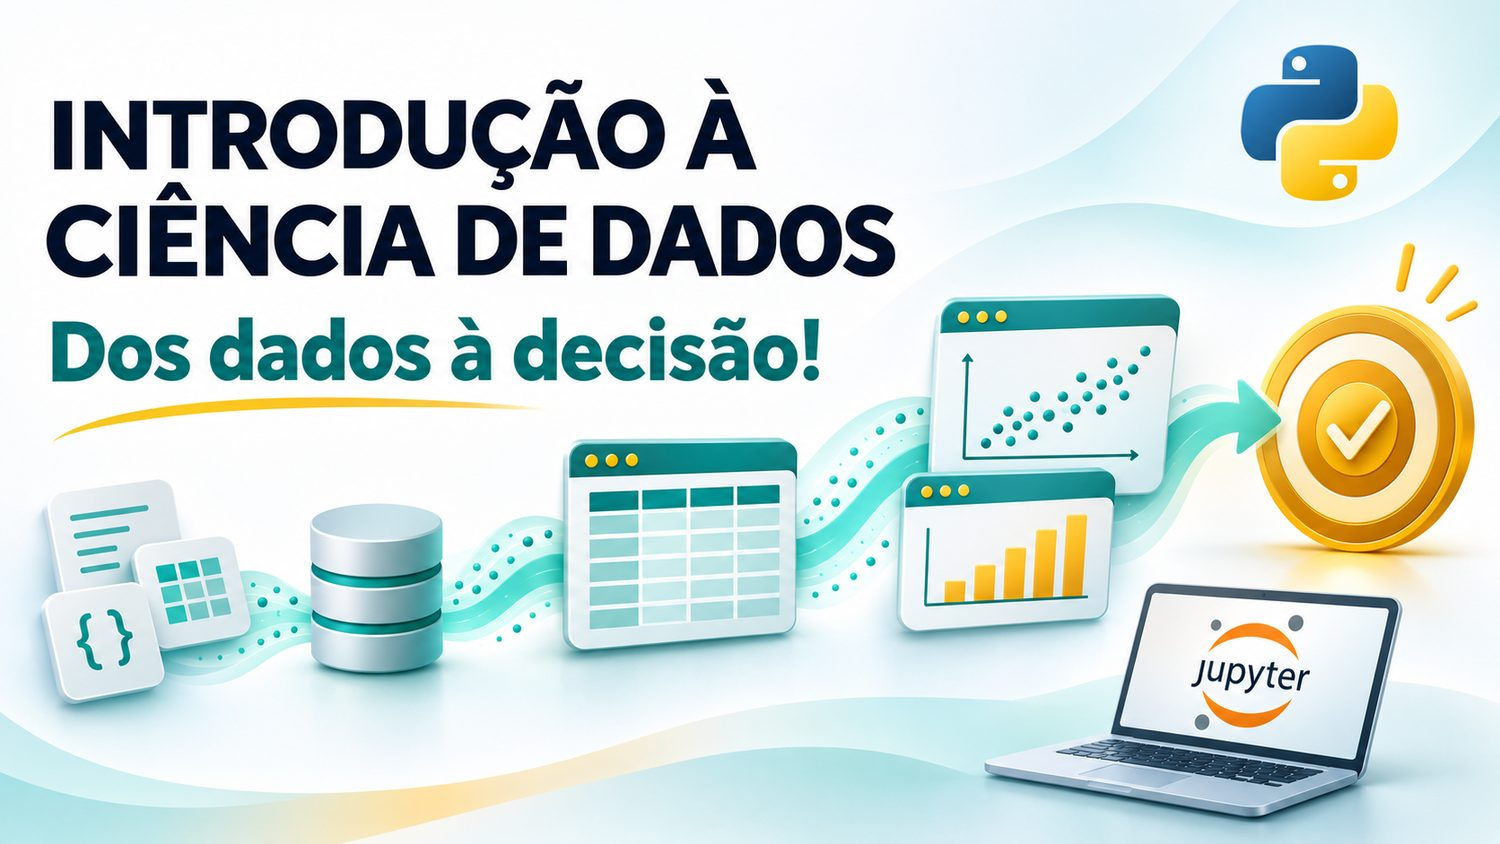

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_aprendizagem_nao_supervisionada/03_Agrupamento_Hierarquico.ipynb)

# Capítulo 3 – Agrupamento hierárquico

O K-Means obriga a escolher o número de grupos antes de começar e dá uma única divisão. O **agrupamento hierárquico** faz o contrário: constrói uma **árvore de fusões**, do pormenor máximo (cada utilizador é um grupo) até um único grupo com todos, e deixa para o fim a decisão de onde cortar. Este capítulo implementa o algoritmo de raiz, ensina a ler um dendrograma e compara os critérios de ligação.

> **Objetivos:** descrever o algoritmo aglomerativo; calcular à mão as primeiras fusões; implementá-lo em NumPy; ler e cortar um dendrograma; comparar as ligações simples, completa, média e de Ward; saber quando preferir o agrupamento hierárquico ao K-Means.

**Pré-requisitos:** capítulos 1 e 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## A ideia: juntar os mais parecidos, repetidamente

O algoritmo **aglomerativo** tem uma só regra, aplicada até não haver mais nada para juntar:

1. no início, cada ponto é um grupo;
2. encontram-se os **dois grupos mais próximos** e juntam-se num só;
3. repete-se o passo 2 até restar um único grupo.

Com n pontos fazem-se n − 1 fusões. O registo dessas fusões, e da distância a que cada uma aconteceu, é o resultado do algoritmo.

Um exemplo pequeno, com seis utilizadores e duas colunas já normalizadas.

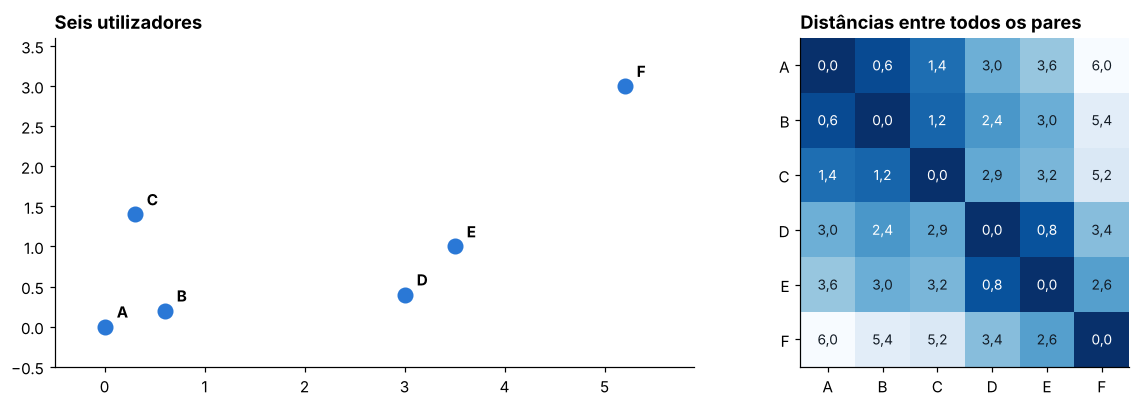

In [2]:
nomes = list("ABCDEF")
pontos = np.array([[0.0, 0.0], [0.6, 0.2], [0.3, 1.4], [3.0, 0.4], [3.5, 1.0], [5.2, 3.0]])
distancias = np.sqrt(((pontos[:, None, :] - pontos[None, :, :]) ** 2).sum(axis=2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax1.scatter(pontos[:, 0], pontos[:, 1], s=90, color=AZUL, zorder=3)
for nome, (x, y) in zip(nomes, pontos):
    ax1.annotate(nome, (x, y), textcoords="offset points", xytext=(8, 6), fontweight="bold")
ax1.set_xlim(-0.5, 5.9)
ax1.set_ylim(-0.5, 3.6)
ax1.set_title("Seis utilizadores")
imagem = ax2.imshow(distancias, cmap="Blues_r", vmax=6)
for i in range(6):
    for j in range(6):
        ax2.text(j, i, f"{distancias[i, j]:.1f}".replace(".", ","), ha="center", va="center", fontsize=9, color="white" if distancias[i, j] < 2.5 else TINTA)
ax2.set_xticks(range(6), nomes)
ax2.set_yticks(range(6), nomes)
ax2.grid(False)
ax2.set_title("Distâncias entre todos os pares")
plt.tight_layout()
plt.show()

A tabela da direita é o ponto de partida: a **matriz de distâncias** entre todos os pares. A menor distância fora da diagonal é entre A e B (0,6): são os primeiros a juntar-se.

Depois dessa fusão aparece uma pergunta nova: qual é a distância entre o grupo {A, B} e o ponto C? Há mais do que uma resposta razoável, e cada uma dá um algoritmo diferente.

## A distância entre grupos: os critérios de ligação

| Ligação | Distância entre dois grupos | Tende a produzir |
| --- | --- | --- |
| **Simples** (*single*) | A do par de pontos **mais próximo** | Grupos alongados, em cadeia |
| **Completa** (*complete*) | A do par de pontos **mais afastado** | Grupos compactos, de diâmetro parecido |
| **Média** (*average*) | A **média** de todos os pares | Um meio-termo |
| **Ward** | O **aumento da inércia** que a fusão provocaria | Grupos compactos e de tamanho parecido, como o K-Means |

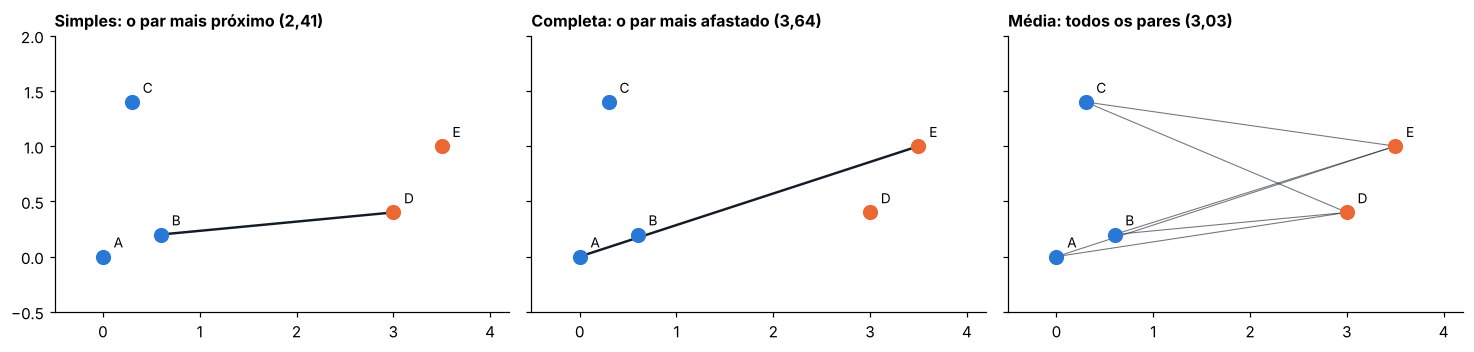

In [3]:
grupo_1, grupo_2 = [0, 1, 2], [3, 4]                      # {A, B, C} e {D, E}
bloco = distancias[np.ix_(grupo_1, grupo_2)]
i_min, j_min = np.unravel_index(bloco.argmin(), bloco.shape)
i_max, j_max = np.unravel_index(bloco.argmax(), bloco.shape)

fig, eixos = plt.subplots(1, 3, figsize=(13.5, 3.3), sharey=True)
titulos = [f"Simples: o par mais próximo ({bloco.min():.2f})", f"Completa: o par mais afastado ({bloco.max():.2f})", f"Média: todos os pares ({bloco.mean():.2f})"]
for ax, titulo in zip(eixos, titulos):
    ax.scatter(pontos[grupo_1, 0], pontos[grupo_1, 1], s=80, color=AZUL, zorder=3)
    ax.scatter(pontos[grupo_2, 0], pontos[grupo_2, 1], s=80, color=LARANJA, zorder=3)
    for nome, (x, y) in zip(nomes[:5], pontos[:5]):
        ax.annotate(nome, (x, y), textcoords="offset points", xytext=(7, 6), fontsize=9)
    ax.set_xlim(-0.5, 4.2)
    ax.set_ylim(-0.5, 2)
    ax.set_title(titulo.replace(".", ","), fontsize=10.5)
eixos[0].plot(*zip(pontos[grupo_1[i_min]], pontos[grupo_2[j_min]]), color=TINTA, lw=1.6)
eixos[1].plot(*zip(pontos[grupo_1[i_max]], pontos[grupo_2[j_max]]), color=TINTA, lw=1.6)
for i in grupo_1:
    for j in grupo_2:
        eixos[2].plot(*zip(pontos[i], pontos[j]), color=TINTA, lw=0.7, alpha=0.6)
plt.tight_layout()
plt.show()

Os mesmos dois grupos estão a distâncias diferentes conforme o critério. Na ligação simples, basta **um** par de pontos próximos para dois grupos se juntarem; na completa, é preciso que **todos** os pontos estejam razoavelmente perto.

## Implementar de raiz

In [4]:
def distancia_entre_grupos(D, a, b, ligacao):
    bloco = D[np.ix_(a, b)]
    return {"simples": bloco.min(), "completa": bloco.max(), "media": bloco.mean()}[ligacao]


def aglomerar(D, ligacao="completa"):
    """Agrupamento aglomerativo. Devolve a lista de fusões: (grupo, grupo, distância)."""
    grupos = [[i] for i in range(len(D))]
    fusoes = []
    while len(grupos) > 1:
        melhor = (None, None, np.inf)
        for i in range(len(grupos)):                        # procura o par de grupos mais próximo
            for j in range(i + 1, len(grupos)):
                d = distancia_entre_grupos(D, grupos[i], grupos[j], ligacao)
                if d < melhor[2]:
                    melhor = (i, j, d)
        i, j, d = melhor
        fusoes.append((grupos[i], grupos[j], d))
        grupos = [g for indice, g in enumerate(grupos) if indice not in (i, j)] + [grupos[i] + grupos[j]]
    return fusoes


for passo, (a, b, d) in enumerate(aglomerar(distancias, "completa"), start=1):
    print(f"Fusão {passo}: {{{', '.join(nomes[i] for i in a)}}} + {{{', '.join(nomes[i] for i in b)}}}  à distância {d:.2f}")

Fusão 1: {A} + {B}  à distância 0.63
Fusão 2: {D} + {E}  à distância 0.78
Fusão 3: {C} + {A, B}  à distância 1.43
Fusão 4: {F} + {D, E}  à distância 3.41
Fusão 5: {C, A, B} + {F, D, E}  à distância 6.00


As cinco fusões contam a história dos dados: primeiro juntam-se os pares mais parecidos (A com B, D com E); depois C entra no grupo de A e B, e F, que está longe de todos, no de D e E; a última fusão, a mais alta, liga as duas metades.

Esta versão é propositadamente simples. Em cada passo volta a comparar todos os pares de grupos, o que a torna lenta. As implementações das bibliotecas atualizam a matriz de distâncias em vez de a recalcular.

## O dendrograma

O **dendrograma** desenha as fusões como uma árvore. Usamos a biblioteca SciPy, que já vem instalada com o scikit-learn.

As distâncias das fusões, calculadas pelo SciPy:

 [0.63 0.78 1.43 3.41 6.  ]
As da nossa implementação:                       [0.63 0.78 1.43 3.41 6.  ]


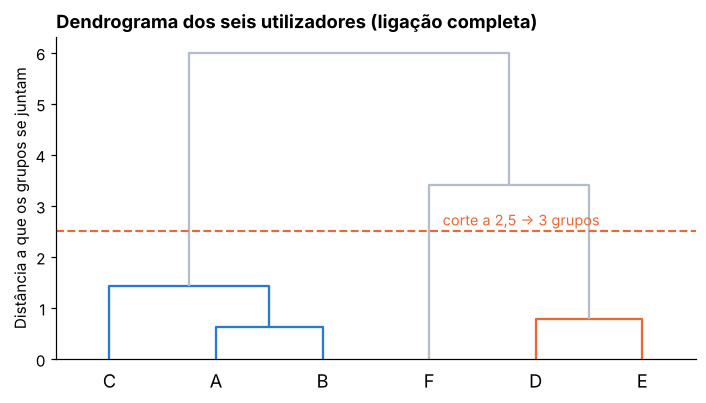

In [5]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette

set_link_color_palette([AZUL, LARANJA, VERDE, VIOLETA])

arvore = linkage(pontos, method="complete")
print("As distâncias das fusões, calculadas pelo SciPy:", arvore[:, 2].round(2))
print("As da nossa implementação:                      ", np.round([d for _, _, d in aglomerar(distancias, "completa")], 2))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
dendrogram(arvore, labels=nomes, ax=ax, color_threshold=2.5, above_threshold_color=CINZA)
ax.axhline(2.5, color=LARANJA, ls="--", lw=1.4)
ax.text(51, 2.62, "corte a 2,5 → 3 grupos", color=LARANJA, ha="right", fontsize=9.5)
ax.set_ylabel("Distância a que os grupos se juntam")
ax.set_title("Dendrograma dos seis utilizadores (ligação completa)")
ax.grid(axis="x", visible=False)
plt.show()

Como ler:

- em baixo estão os pontos; cada **ponte horizontal** é uma fusão;
- a **altura** da ponte é a distância a que os dois grupos se juntaram. Pontes baixas ligam coisas muito parecidas; pontes altas ligam coisas diferentes;
- a ordem dos pontos no eixo horizontal é escolhida para as linhas não se cruzarem. A proximidade horizontal entre duas folhas **não** quer dizer nada: só a altura da ponte que as liga conta.

### Cortar a árvore

Para obter grupos, traça-se uma **linha horizontal**. Cada ramo que a linha atravessa é um grupo. Um corte a 2,5 dá três grupos: {A, B, C}, {D, E} e {F}. Um corte mais acima dá dois; mais abaixo, quatro ou cinco.

Um bom sítio para cortar é um **intervalo grande sem fusões**: quer dizer que os grupos existentes são bem mais parecidos por dentro do que entre si.

É a grande diferença em relação ao K-Means: **a árvore faz-se uma vez, e dela tiram-se agrupamentos para qualquer número de grupos**, coerentes uns com os outros. O agrupamento em três grupos obtém-se partindo um dos grupos do agrupamento em dois.

## Os utilizadores da aplicação

Voltamos ao caso do módulo. O agrupamento hierárquico precisa da matriz de distâncias entre todos os pares, cujo tamanho cresce com o **quadrado** do número de pontos: 3 000 utilizadores são 4,5 milhões de pares. Para o dendrograma ser legível, usamos uma amostra de 300.

In [6]:
def gerar_utilizadores(n=3000, semente=53, com_perfil=False):
    """Gera utilizadores de uma aplicação fictícia de aprendizagem de línguas (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    perfil = rng.choice(4, n, p=[0.34, 0.22, 0.30, 0.14])
    # por perfil: sessões por semana, minutos por sessão, dias seguidos, % à noite, exercícios de fala, % de erros
    centros = np.array([[9.5, 6.0, 38, 30, 2.0, 22],
                        [2.2, 34.0, 3, 55, 6.0, 17],
                        [1.3, 7.0, 1, 45, 0.6, 31],
                        [7.5, 27.0, 55, 40, 14.0, 12]])
    desvios = np.array([[2.2, 1.8, 22, 16, 1.6, 6], [0.8, 8.0, 2.5, 18, 3.0, 5], [0.7, 3.0, 1.2, 20, 0.7, 8], [2.0, 7.0, 30, 17, 5.0, 4]])
    v = rng.normal(centros[perfil], desvios[perfil])
    sessoes = v[:, 0].clip(0.2, 21).round(1)
    minutos = v[:, 1].clip(2, 70).round(1)
    licoes = (sessoes * minutos / 5.5 * rng.normal(1, 0.12, n)).clip(0.2).round(1)
    tabela = pd.DataFrame({"sessoes_semana": sessoes, "minutos_sessao": minutos, "licoes_semana": licoes,
                           "dias_seguidos": v[:, 2].clip(0, 200).round(), "pct_noite": v[:, 3].clip(0, 100).round(),
                           "exercicios_fala": v[:, 4].clip(0, 40).round(1), "pct_erros": v[:, 5].clip(2, 60).round(1),
                           "meses_na_app": rng.gamma(1.8, 5, n).clip(0.5, 48).round(1)})
    tabela["premium"] = rng.random(n) < np.array([0.12, 0.25, 0.03, 0.55])[perfil]
    if com_perfil:                                   # só para verificação: num caso real esta coluna não existe
        tabela["perfil_verdadeiro"] = perfil
    return tabela


utilizadores = gerar_utilizadores()
utilizadores.head()

,sessoes_semana,minutos_sessao,licoes_semana,dias_seguidos,pct_noite,exercicios_fala,pct_erros,meses_na_app,premium
0,10.3,9.2,11.2,25.0,49.0,0.9,15.8,17.9,False
1,1.4,7.0,1.7,0.0,62.0,0.0,32.3,3.2,False
2,9.5,5.1,8.7,52.0,58.0,3.7,28.6,22.9,False
3,2.7,25.2,13.0,29.0,52.0,13.3,13.1,8.4,False
4,11.7,8.2,15.5,39.0,14.0,0.0,21.7,16.4,False


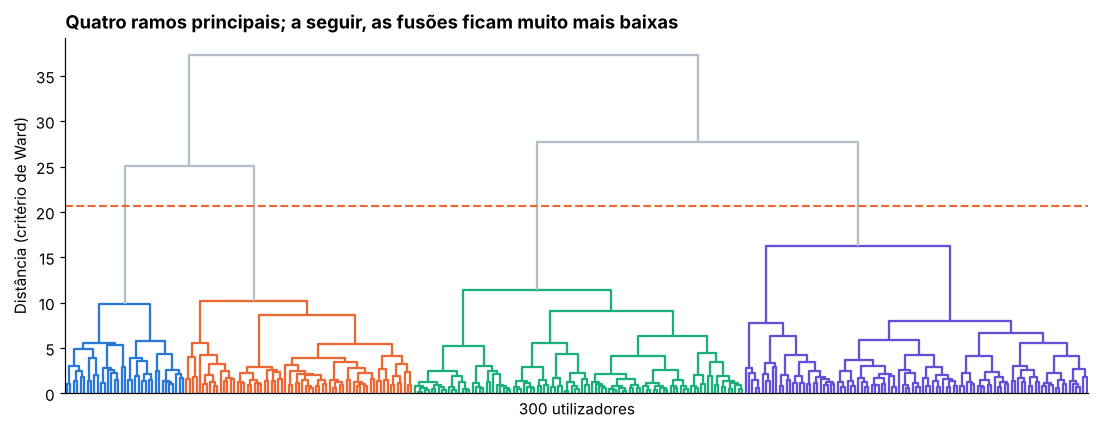

In [7]:
from sklearn.preprocessing import StandardScaler

numericas = [c for c in utilizadores.columns if c != "premium"]
Z = StandardScaler().fit_transform(utilizadores[numericas])
amostra = np.random.default_rng(0).choice(len(Z), 300, replace=False)
ward = linkage(Z[amostra], method="ward")

fig, ax = plt.subplots(figsize=(12, 4.2))
corte = (ward[-4, 2] + ward[-3, 2]) / 2
dendrogram(ward, no_labels=True, color_threshold=corte, above_threshold_color=CINZA, ax=ax)
ax.axhline(corte, color=LARANJA, ls="--", lw=1.4)
ax.set_ylabel("Distância (critério de Ward)")
ax.set_xlabel("300 utilizadores")
ax.set_title("Quatro ramos principais; a seguir, as fusões ficam muito mais baixas")
ax.grid(axis="x", visible=False)
plt.show()

Com centenas de folhas já não se leem indivíduos: lê-se a **forma**. Há quatro ramos compridos que só se juntam a grande altura, e por baixo deles as fusões são todas baixas. A linha tracejada corta nesse intervalo e dá quatro grupos.

As alturas das últimas fusões mostram o mesmo em números:

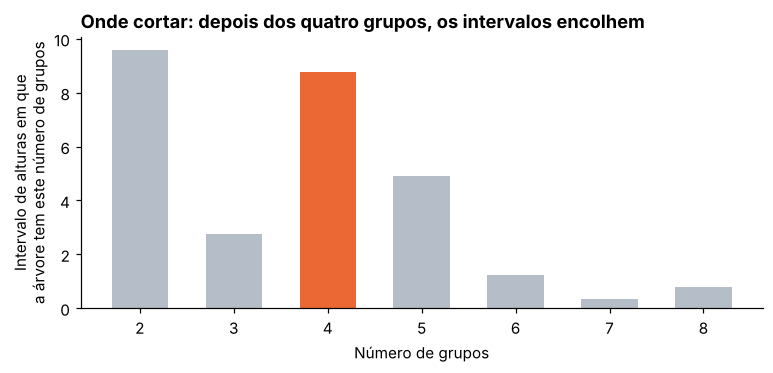

,Altura da fusão,Salto para a fusão anterior
Grupos depois da fusão,,
1,37.3,9.6
2,27.8,2.7
3,25.0,8.8
4,16.3,4.9
5,11.4,1.2
6,10.1,0.3
7,9.8,0.8
8,9.0,NaN


In [8]:
ultimas = pd.DataFrame({"Grupos depois da fusão": range(1, 9), "Altura da fusão": ward[::-1, 2][:8]}).set_index("Grupos depois da fusão")
ultimas["Salto para a fusão anterior"] = ultimas["Altura da fusão"] - ultimas["Altura da fusão"].shift(-1)

fig, ax = plt.subplots(figsize=(8, 3.2))
barras = ax.bar(ultimas.index[1:], ultimas["Altura da fusão"].shift(1).dropna() - ultimas["Altura da fusão"][1:], color=[LARANJA if k == 4 else CINZA for k in ultimas.index[1:]], width=0.6)
ax.set_xlabel("Número de grupos")
ax.set_ylabel("Intervalo de alturas em que\na árvore tem este número de grupos")
ax.set_title("Onde cortar: depois dos quatro grupos, os intervalos encolhem")
plt.show()
ultimas.round(1)

Cada barra mede o intervalo de alturas em que um corte dá esse número de grupos. O intervalo de dois grupos é grande, como quase sempre: a última fusão junta as duas metades mais diferentes dos dados. O que interessa é o **último intervalo grande antes de as barras encolherem**: quatro grupos. É o equivalente ao cotovelo do capítulo anterior.

### O critério de ligação muda tudo

In [9]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

verdade = gerar_utilizadores(com_perfil=True)["perfil_verdadeiro"].to_numpy()
linhas = {}
for nome, metodo in [("Ward", "ward"), ("Completa", "complete"), ("Média", "average"), ("Simples", "single")]:
    grupos = AgglomerativeClustering(n_clusters=4, linkage=metodo).fit_predict(Z)
    linhas[nome] = {"tamanho dos 4 grupos": ", ".join(str(n) for n in sorted(np.bincount(grupos), reverse=True)), "silhueta": round(silhouette_score(Z, grupos), 2),
                    "concordância com os perfis": round(adjusted_rand_score(verdade, grupos), 2)}
kmeans = KMeans(4, n_init=10, random_state=0).fit_predict(Z)
linhas["K-Means (para comparar)"] = {"tamanho dos 4 grupos": ", ".join(str(n) for n in sorted(np.bincount(kmeans), reverse=True)), "silhueta": round(silhouette_score(Z, kmeans), 2),
                                     "concordância com os perfis": round(adjusted_rand_score(verdade, kmeans), 2)}
pd.DataFrame(linhas).T

,tamanho dos 4 grupos,silhueta,concordância com os perfis
Ward,"1067, 910, 619, 404",0.34,0.97
Completa,"2490, 193, 188, 129",0.18,0.17
Média,"2582, 406, 10, 2",0.29,0.21
Simples,"2997, 1, 1, 1",0.28,0.0
K-Means (para comparar),"1081, 901, 630, 388",0.34,0.97


A coluna dos tamanhos conta quase tudo.

- **Ward** dá quatro grupos equilibrados, praticamente iguais aos do K-Means. Não é coincidência: os dois minimizam a mesma coisa, a inércia.
- **Simples** dá um grupo com quase todos os utilizadores e três grupos minúsculos. É o **efeito de cadeia**: basta um ponto intermédio entre dois grupos para eles se fundirem, e os valores extremos ficam isolados.
- **Completa** e **média** ficam a meio caminho, com um grupo muito grande e outros pequenos.

Nestes dados, em que os grupos são nuvens arredondadas com alguma sobreposição, Ward é a escolha certa. A ligação simples tem o seu uso: é a única que consegue seguir formas alongadas ou curvas.

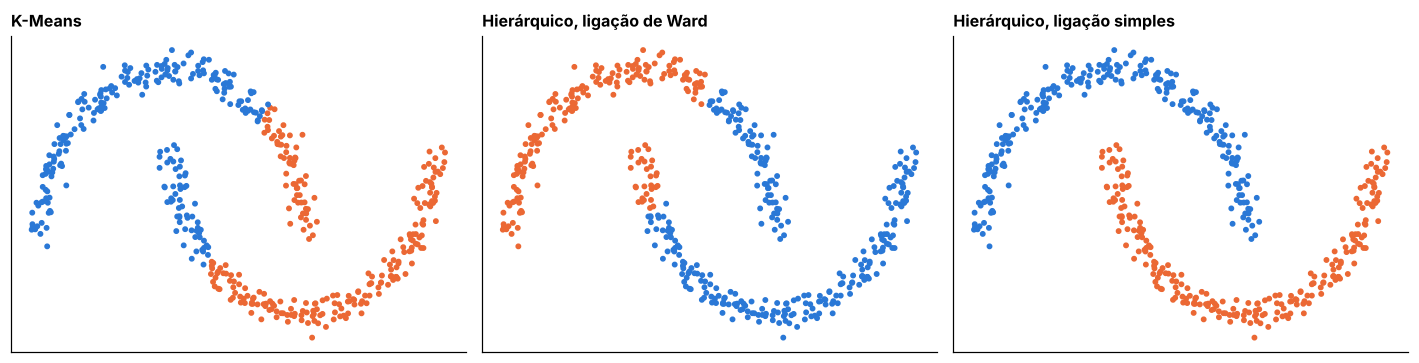

In [10]:
from sklearn.datasets import make_moons

luas, _ = make_moons(500, noise=0.05, random_state=0)
CORES = [AZUL, LARANJA]
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (titulo, grupos) in zip(eixos, [("K-Means", KMeans(2, n_init=10, random_state=0).fit_predict(luas)),
                                        ("Hierárquico, ligação de Ward", AgglomerativeClustering(2, linkage="ward").fit_predict(luas)),
                                        ("Hierárquico, ligação simples", AgglomerativeClustering(2, linkage="single").fit_predict(luas))]):
    ax.scatter(luas[:, 0], luas[:, 1], s=8, color=[CORES[g] for g in grupos])
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Nas duas «luas», o K-Means e a ligação de Ward cortam as formas ao meio. A ligação simples, que avança de vizinho em vizinho, segue cada lua até ao fim. O efeito de cadeia, que era um defeito nos utilizadores, é aqui a qualidade que resolve o problema.

> Não há um critério de ligação melhor em geral. Cada um corresponde a uma **ideia diferente do que é um grupo**: compacto (Ward, completa) ou contínuo (simples).

## Uma hierarquia de perfis

A árvore dá uma leitura que o K-Means não dá: **como é que os grupos se relacionam entre si**. Cortamos a mesma árvore em dois, três e quatro grupos e seguimos as divisões.

In [11]:
arvore_total = linkage(Z, method="ward")
cortes = pd.DataFrame({k: fcluster(arvore_total, t=k, criterion="maxclust") for k in [2, 3, 4]})
resumo = utilizadores[["sessoes_semana", "minutos_sessao", "dias_seguidos", "exercicios_fala", "pct_erros"]].join(cortes)
for k in [2, 3, 4]:
    print(f"--- {k} grupos")
    print(resumo.groupby(k).agg(utilizadores=("sessoes_semana", "size"), sessoes=("sessoes_semana", "mean"), minutos=("minutos_sessao", "mean"),
                                dias_seguidos=("dias_seguidos", "mean"), fala=("exercicios_fala", "mean"), erros=("pct_erros", "mean")).round(1))

--- 2 grupos
   utilizadores  sessoes  minutos  dias_seguidos  fala  erros
2                                                            
1          1023      4.3     31.2           24.4   9.2   15.3
2          1977      5.8      6.5           22.0   1.5   26.1
--- 3 grupos
   utilizadores  sessoes  minutos  dias_seguidos  fala  erros
3                                                            
1          1023      4.3     31.2           24.4   9.2   15.3
2          1067      9.5      6.0           39.1   2.1   22.3
3           910      1.5      7.1            2.1   0.7   30.5
--- 4 grupos
   utilizadores  sessoes  minutos  dias_seguidos  fala  erros
4                                                            
1           619      2.2     33.8            3.1   5.9   17.4
2           404      7.5     27.2           57.1  14.1   12.1
3          1067      9.5      6.0           39.1   2.1   22.3
4           910      1.5      7.1            2.1   0.7   30.5


In [12]:
print(pd.crosstab(cortes[2], cortes[4], rownames=["corte em 2 grupos"], colnames=["corte em 4 grupos"]))

corte em 4 grupos    1    2     3    4
corte em 2 grupos                     
1                  619  404     0    0
2                    0    0  1067  910


A tabela cruzada mostra a hierarquia: cada um dos quatro grupos cai **inteiro** dentro de um dos dois grupos do corte mais alto. A primeira divisão separa quem faz **sessões longas** de quem faz **sessões curtas**. As seguintes distinguem, dentro de cada lado, os utilizadores muito ativos dos pouco ativos: os de sessões curtas dividem-se em «hábito diário» e «a desistir»; os de sessões longas, em «intensivos» e «fim de semana».

Para comunicar, esta estrutura é útil. Quem decide pode querer apenas dois segmentos; a equipa de produto pode querer os quatro. Com a árvore, os dois níveis de pormenor são compatíveis.

## K-Means ou hierárquico?

| | K-Means | Hierárquico aglomerativo |
| --- | --- | --- |
| Número de grupos | Escolhe-se antes | Escolhe-se depois, cortando a árvore |
| Resultado | Uma divisão | Uma árvore de divisões encaixadas |
| Repetibilidade | Depende do arranque | Sempre o mesmo resultado |
| Forma dos grupos | Arredondada | Depende da ligação |
| Custo | Baixo; serve para milhões de pontos | Cresce com o quadrado de n; alguns milhares de pontos |
| Casos novos | `predict`: o centroide mais próximo | Não tem `predict`; é preciso refazer ou usar outro modelo |
| Visualização | Perfis dos centroides | Dendrograma |

Usa-se muitas vezes uma combinação: um agrupamento hierárquico numa **amostra**, para perceber a estrutura e escolher o número de grupos, seguido de um K-Means em **todos** os dados com esse número.

## Exercícios

### `Exercício 1` – À mão, com ligação simples

Refaz as fusões dos seis utilizadores A a F com a ligação **simples**, usando a matriz de distâncias do início do capítulo. A ordem das fusões é a mesma da ligação completa? E as distâncias?

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for passo, (a, b, d) in enumerate(aglomerar(distancias, "simples"), start=1):
    print(f"Fusão {passo}: {{{', '.join(nomes[i] for i in a)}}} + {{{', '.join(nomes[i] for i in b)}}}  à distância {d:.2f}")
```

As três primeiras fusões são as mesmas: A + B, D + E, e C com {A, B}. As duas primeiras acontecem à mesma distância (entre pontos isolados não há diferença entre critérios); a terceira acontece mais cedo, porque a ligação simples usa sempre o par mais próximo. Depois a ordem **muda**: na ligação simples os dois grupos juntam-se logo (basta o par B–D, a 2,41), e F fica para o fim; na completa, F juntava-se primeiro a {D, E}. O critério de ligação pode mudar a própria árvore, e não só as alturas.

</details>

### `Exercício 2` – A ligação de Ward de raiz

A ligação de Ward junta os dois grupos cuja fusão **menos aumenta a inércia**. Escreve uma função `aumento_da_inercia(Z, a, b)` que calcule a inércia do grupo fundido menos a soma das inércias dos dois grupos. Usa-a para confirmar, nos seis pontos, que a primeira fusão é A + B.

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def inercia_do_grupo(Z, indices):
    return float(((Z[indices] - Z[indices].mean(axis=0)) ** 2).sum())


def aumento_da_inercia(Z, a, b):
    return inercia_do_grupo(Z, a + b) - inercia_do_grupo(Z, a) - inercia_do_grupo(Z, b)


aumentos = {nomes[i] + nomes[j]: aumento_da_inercia(pontos, [i], [j]) for i in range(6) for j in range(i + 1, 6)}
print(pd.Series(aumentos).sort_values().head(4).round(2))
```

O menor aumento é o da fusão A + B. Para dois pontos isolados, o aumento é metade do quadrado da distância entre eles, e por isso a primeira fusão coincide com a dos outros critérios. A diferença aparece quando os grupos têm vários membros: Ward penaliza a fusão de grupos grandes, o que explica os tamanhos equilibrados.

</details>

### `Exercício 3` – O dendrograma com outra ligação

Desenha o dendrograma da mesma amostra de 300 utilizadores com a ligação **simples**. Compara a forma com a do dendrograma de Ward. Como se vê o efeito de cadeia?

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
fig, ax = plt.subplots(figsize=(12, 3.6))
dendrogram(linkage(Z[amostra], method="single"), no_labels=True, color_threshold=0, above_threshold_color=CINZA, ax=ax)
ax.grid(axis="x", visible=False)
plt.show()
```

Em vez de ramos largos que se juntam no topo, vê-se uma **escada**: um grupo grande que vai engolindo um ponto de cada vez, a alturas cada vez um pouco maiores. Não há nenhum intervalo grande sem fusões, e qualquer corte dá um grupo enorme e alguns pontos isolados. É a assinatura do efeito de cadeia.

</details>

### `Exercício 4` – Hierárquico na amostra, K-Means em todos

Corta a árvore de Ward da amostra de 300 utilizadores em quatro grupos e calcula o centroide de cada um. Usa esses centroides como ponto de partida de um K-Means em todos os dados (`KMeans(4, init=centroides, n_init=1)`). O resultado coincide com o do K-Means habitual?

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
grupos_amostra = fcluster(ward, t=4, criterion="maxclust")
centroides = np.array([Z[amostra][grupos_amostra == g].mean(axis=0) for g in range(1, 5)])
combinado = KMeans(4, init=centroides, n_init=1).fit(Z)
print(f"Concordância com o K-Means habitual: {adjusted_rand_score(kmeans, combinado.labels_):.3f} | iterações: {combinado.n_iter_}")
```

Os dois agrupamentos coincidem, e o K-Means converge em poucas iterações porque já parte de perto da solução. A amostra serviu para ver a estrutura e escolher o número de grupos; o K-Means estendeu o resultado aos 3 000 utilizadores a baixo custo.

</details>

## Verifica o que aprendeste

- [ ] Sei descrever o algoritmo aglomerativo.
- [ ] Sei calcular as primeiras fusões a partir de uma matriz de distâncias.
- [ ] Sei explicar as ligações simples, completa, média e de Ward.
- [ ] Sei ler um dendrograma e escolher onde cortar.
- [ ] Sei o que é o efeito de cadeia, e quando é um defeito ou uma qualidade.
- [ ] Sei comparar o agrupamento hierárquico com o K-Means.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering
- https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html
- https://en.wikipedia.org/wiki/Hierarchical_clustering